In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from PIL import Image
import os

root = "/content/drive/MyDrive/Simmi_PHD/Training_data"

for folder, _, files in os.walk(root):
    for file in files:
        path = os.path.join(folder, file)
        try:
            with Image.open(path) as img:
                img.verify()
        except Exception:
            print("Deleting:", path)
            os.remove(path)

Inceptionv3

In [ ]:
import os
import torch
import torch.nn as nn
from torchvision import datasets

from torchvision.models import inception_v3, Inception_V3_Weights
from torch.utils.data import DataLoader, random_split
from tqdm import tqdm
import pickle

# ------------------------
# Paths & Setup
# ------------------------
data_dir = "/content/drive/MyDrive/Simmi_PHD/Testing_data"
checkpoint_dir = "/content/drive/MyDrive/Simmi_PHD/Weights/Inception_v3"
os.makedirs(checkpoint_dir, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ------------------------
# Model & Transform
# ------------------------
weights = Inception_V3_Weights.DEFAULT
transform = weights.transforms()



import torch.nn as nn
from torchvision.models import inception_v3, Inception_V3_Weights

class InceptionBinary(nn.Module):
    def __init__(self):
        super().__init__()
        weights = Inception_V3_Weights.DEFAULT
        self.model = inception_v3(weights=weights, aux_logits=True)  # Or aux_logits=False
        in_features = self.model.fc.in_features
        self.model.fc = nn.Sequential(
            nn.Linear(in_features, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        out = self.model(x)
        if isinstance(out, tuple):
            out = out[0]  # when aux_logits=True
        return out




model = InceptionBinary().to(device)
# ------------------------
# Dataset & Dataloader
# ------------------------
full_dataset = datasets.ImageFolder(root=data_dir, transform=transform)

# Split 80/20
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size)

# ------------------------
# Loss & Optimizer
# ------------------------
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

# ------------------------
# Training Setup
# ------------------------
num_epochs = 50
best_val_loss = float('inf')
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 140MB/s]


In [ ]:
# ------------------------
# Training Loop
# ------------------------
for epoch in tqdm(range(1, num_epochs + 1), desc="Epochs"):
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.float().unsqueeze(1).to(device)  # shape: (B, 1)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        preds = (outputs > 0.5).float()
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # Validation
    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.float().unsqueeze(1).to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)
            preds = (outputs > 0.5).float()
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    # Save best model
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), os.path.join(checkpoint_dir, "best_weights.pth"))

    # Save model and history every 10 epochs
    if epoch % 5  == 0:
        torch.save(model.state_dict(), os.path.join(checkpoint_dir, f"epoch_{epoch}_weights.pth"))
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        with open(os.path.join(checkpoint_dir, "training_history.pkl"), "wb") as f:
            pickle.dump(history, f)

    # Print status
    print(f"Epoch {epoch:2d}: "
          f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}, "
          f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

Epochs:   2%|▏         | 1/50 [01:51<1:30:43, 111.08s/it]

Epoch  1: Train Loss: 0.5061, Train Acc: 0.8359, Val Loss: 0.3773, Val Acc: 0.8788


Epochs:   4%|▍         | 2/50 [01:59<40:24, 50.51s/it]   

Epoch  2: Train Loss: 0.1392, Train Acc: 0.9771, Val Loss: 0.2292, Val Acc: 0.9242


Epochs:   6%|▌         | 3/50 [02:07<24:23, 31.14s/it]

...

Epoch 48: Train Loss: 0.0068, Train Acc: 1.0000, Val Loss: 0.0481, Val Acc: 0.9697


Epochs:  98%|█████████▊| 49/50 [08:19<00:08,  8.40s/it]

Epoch 49: Train Loss: 0.0086, Train Acc: 1.0000, Val Loss: 0.0626, Val Acc: 0.9697


Epochs: 100%|██████████| 50/50 [08:27<00:00, 10.15s/it]

Epoch 50: Train Loss: 0.0053, Train Acc: 1.0000, Val Loss: 0.0664, Val Acc: 0.9394


In [ ]:
import os
import torch
import torch.nn as nn
from torchvision.models import inception_v3, Inception_V3_Weights
from torchvision import datasets, transforms

from torchvision.io import read_image
from torchvision.transforms import functional as TF
import pandas as pd
from tqdm import tqdm
import numpy as np

# ----------------------
# Device and Model
# ----------------------
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


weights = Inception_V3_Weights.DEFAULT
transform = weights.transforms()



import torch.nn as nn
from torchvision.models import inception_v3, Inception_V3_Weights

class InceptionBinary(nn.Module):
    def __init__(self):
        super().__init__()
        weights = Inception_V3_Weights.DEFAULT
        self.model = inception_v3(weights=weights, aux_logits=True)  # Or aux_logits=False
        in_features = self.model.fc.in_features
        self.model.fc = nn.Sequential(
            nn.Linear(in_features, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        out = self.model(x)
        if isinstance(out, tuple):
            out = out[0]  # when aux_logits=True
        return out




model = InceptionBinary().to(device)
model.load_state_dict(torch.load("/content/drive/MyDrive/Simmi_PHD/Weights/Inception_v3/epoch_40_weights.pth"))  # ← replace with your path
model.eval()

# ----------------------
# Test folders
# ----------------------
test_root = "/content/drive/MyDrive/Simmi_PHD/Testing_resized_v2"
class_map = {'a_non_cancer': 0, 'b_cancer': 1}

# ----------------------
# Evaluation Loop
# ----------------------
TP = FP = TN = FN = 0
accuracies = []

with torch.no_grad():
    for cls_name, label in class_map.items():
        folder = os.path.join(test_root, cls_name)
        for fname in tqdm(os.listdir(folder), desc=f"Evaluating {cls_name}"):
            if not fname.lower().endswith(('.png', '.jpg', '.jpeg')): continue

            path = os.path.join(folder, fname)
            image = read_image(path).float() / 255.0
            image = transform(image).unsqueeze(0).to(device)

            output = model(image)
            pred = 1 if output.item() > 0.5 else 0

            # Accuracy for deviation
            correct = (pred == label)
            accuracies.append(int(correct))

            # Confusion matrix components
            if pred == 1 and label == 1:
                TP += 1
            elif pred == 1 and label == 0:
                FP += 1
            elif pred == 0 and label == 0:
                TN += 1
            elif pred == 0 and label == 1:
                FN += 1

# ----------------------
# Metrics
# ----------------------
total = TP + FP + TN + FN
accuracy = (TP + TN) / total if total else 0
sensitivity = TP / (TP + FN) if (TP + FN) else 0
specificity = TN / (TN + FP) if (TN + FP) else 0
deviation = np.std(accuracies)

# ----------------------
# Save CSV
# ----------------------
results = {
    'TP': [TP],
    'FP': [FP],
    'TN': [TN],
    'FN': [FN],
    'Accuracy': [round(accuracy, 4)],
    'Sensitivity': [round(sensitivity, 4)],
    'Specificity': [round(specificity, 4)],
    'Accuracy StdDev': [round(deviation, 4)]
}

df = pd.DataFrame(results)
df.to_csv("/content/drive/MyDrive/Simmi_PHD/Results/Inception_v3/InceptionV3_epoch_40.csv", index=False)
print("\n✅ Results saved to 'InceptionV3_top_results.csv'")


Evaluating b_cancer: 100%|██████████| 164/164 [00:04<00:00, 33.51it/s]


✅ Results saved to 'InceptionV3_top_results.csv'


Device: cuda
Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 185MB/s] 



Model loaded successfully:
/content/drive/MyDrive/Classification/Weights/Inception_v3/epoch_40_weights.pth


Evaluating b_cancer: 100%|██████████| 164/164 [00:07<00:00, 22.95it/s]




INCEPTION-V3 TEST RESULTS

Total Images Tested : 328

Confusion Matrix
----------------------------------------
TP : 154
FP : 12
TN : 152
FN : 10

Performance Metrics
----------------------------------------
Accuracy       : 0.9329 (93.29%)
Sensitivity    : 0.9390 (93.90%)
Specificity    : 0.9268 (92.68%)
Precision      : 0.9277 (92.77%)
F1-Score       : 0.9333
Accuracy StdDev: 0.2501

Calibration Metrics
----------------------------------------
ECE            : 0.062148
MCE            : 0.657177
Brier Score    : 0.063149

Discrimination Metrics
----------------------------------------
ROC-AUC        : 0.944750
PR-AUC         : 0.951285

95% Confidence Intervals
----------------------------------------
Accuracy       : 0.9329 (0.9005, 0.9553)
Sensitivity    : 0.9390 (0.8914, 0.9665)
Specificity    : 0.9268 (0.8765, 0.9577)
Precision      : 0.9277 (0.8779, 0.9582)


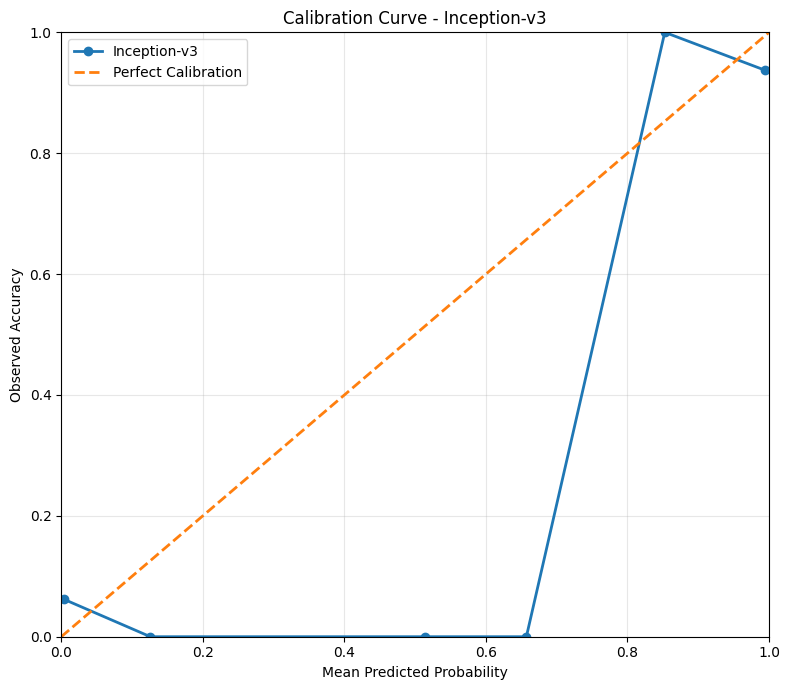

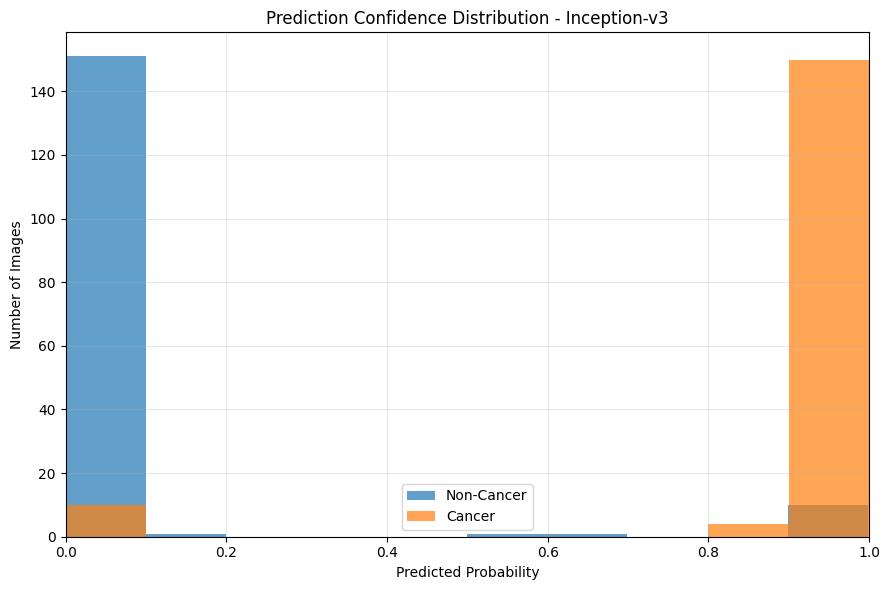

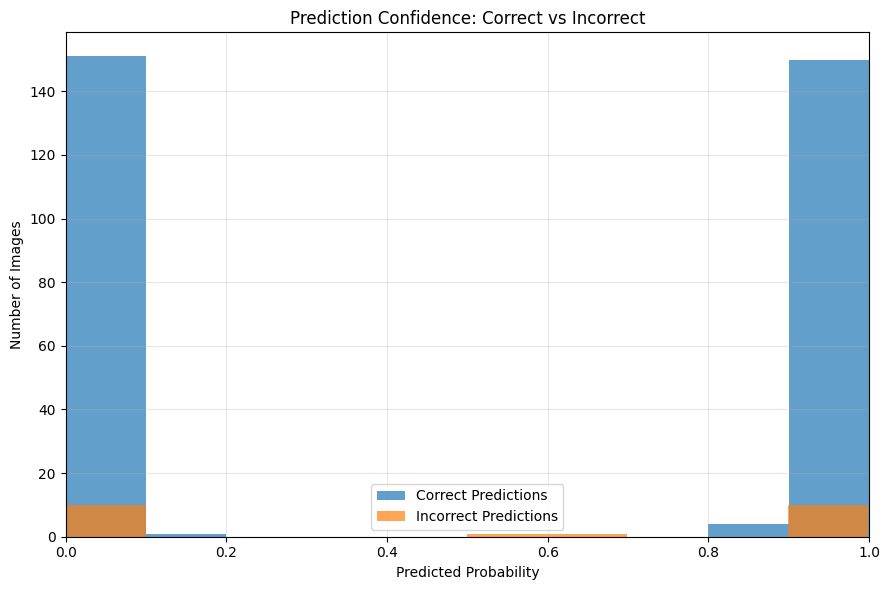

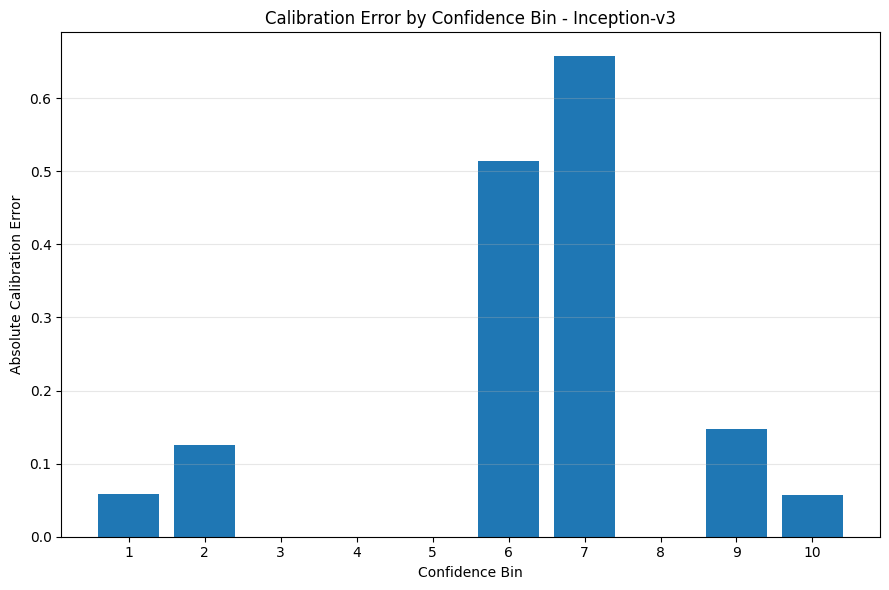

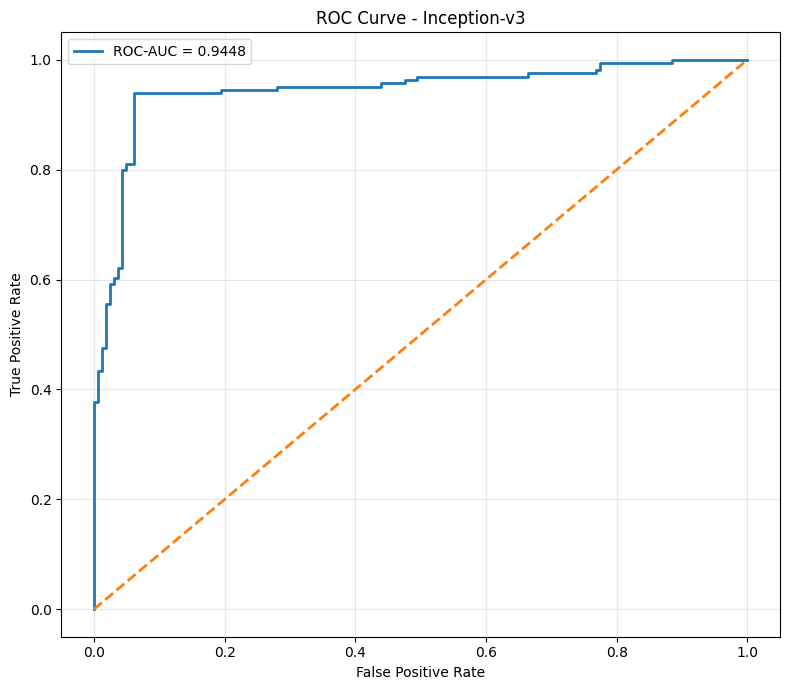

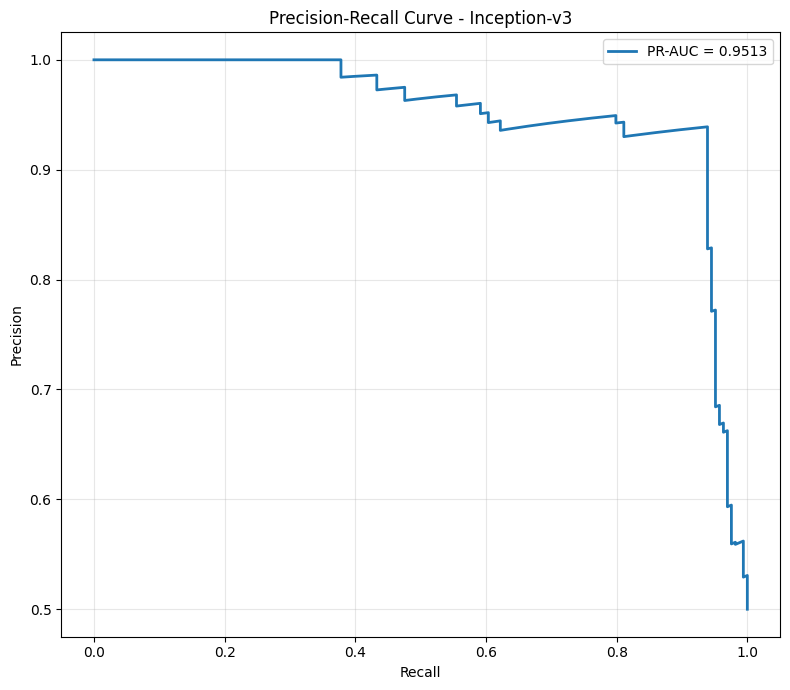



FILES SAVED

Main metrics:
/content/drive/MyDrive/Classification/Results/Inception_v3/calibration_analysis/InceptionV3_epoch_40_all_metrics.csv

Calibration bins:
/content/drive/MyDrive/Classification/Results/Inception_v3/calibration_analysis/InceptionV3_calibration_bins.csv

Detailed predictions:
/content/drive/MyDrive/Classification/Results/Inception_v3/calibration_analysis/InceptionV3_detailed_predictions.csv

Calibration curve:
/content/drive/MyDrive/Classification/Results/Inception_v3/calibration_analysis/InceptionV3_calibration_curve.png

Confidence histogram:
/content/drive/MyDrive/Classification/Results/Inception_v3/calibration_analysis/InceptionV3_confidence_histogram.png

Correct vs incorrect confidence:
/content/drive/MyDrive/Classification/Results/Inception_v3/calibration_analysis/InceptionV3_correct_vs_incorrect_confidence.png

ECE bin plot:
/content/drive/MyDrive/Classification/Results/Inception_v3/calibration_analysis/InceptionV3_ECE_bins.png

ROC curve:
/content/drive

In [3]:
# ============================================================
# INCEPTION-V3
# PERFORMANCE + CALIBRATION METRICS + PLOTS + 95% CI
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torchvision.models import inception_v3, Inception_V3_Weights
from torchvision.io import read_image

from tqdm import tqdm

import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    auc
)

# ============================================================
# 1. DEVICE
# ============================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)


# ============================================================
# 2. PATHS
# ============================================================

weights_path = (
    "/content/drive/MyDrive/Classification/Weights/Inception_v3/"
    "epoch_40_weights.pth"
)

test_root = (
    "/content/drive/MyDrive/Classification/Bt_training_and_testing/Testing_resized_v2"
)

results_dir = (
    "/content/drive/MyDrive/Classification/Results/Inception_v3/calibration_analysis"
)

os.makedirs(results_dir, exist_ok=True)


# ============================================================
# 3. INCEPTION-V3 TRANSFORM
# ============================================================

weights = Inception_V3_Weights.DEFAULT

transform = weights.transforms()


# ============================================================
# 4. MODEL DEFINITION
# ============================================================

class InceptionBinary(nn.Module):

    def __init__(self):

        super().__init__()

        weights = Inception_V3_Weights.DEFAULT

        self.model = inception_v3(
            weights=weights,
            aux_logits=True
        )

        in_features = self.model.fc.in_features

        self.model.fc = nn.Sequential(
            nn.Linear(in_features, 1),
            nn.Sigmoid()
        )

    def forward(self, x):

        out = self.model(x)

        # Inception with aux_logits=True can return
        # an InceptionOutputs object.
        if hasattr(out, "logits"):
            out = out.logits

        elif isinstance(out, tuple):
            out = out[0]

        return out


# ============================================================
# 5. LOAD MODEL
# ============================================================

model = InceptionBinary().to(device)

checkpoint = torch.load(
    weights_path,
    map_location=device
)

# Handle possible checkpoint formats
if isinstance(checkpoint, dict) and "state_dict" in checkpoint:

    checkpoint = checkpoint["state_dict"]

elif isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:

    checkpoint = checkpoint["model_state_dict"]


# Remove possible "module." prefix
clean_checkpoint = {}

for key, value in checkpoint.items():

    new_key = key

    if new_key.startswith("module."):
        new_key = new_key.replace("module.", "", 1)

    clean_checkpoint[new_key] = value


model.load_state_dict(
    clean_checkpoint,
    strict=True
)

model.eval()

print("\nModel loaded successfully:")
print(weights_path)


# ============================================================
# 6. TEST DATA
# ============================================================

class_map = {
    "a_non_cancer": 0,
    "b_cancer": 1
}


# ============================================================
# 7. STORAGE
# ============================================================

TP = 0
FP = 0
TN = 0
FN = 0

accuracies = []

all_probabilities = []
all_predictions = []
all_labels = []
all_filenames = []


# ============================================================
# 8. EVALUATION
# ============================================================

with torch.no_grad():

    for cls_name, label in class_map.items():

        folder = os.path.join(
            test_root,
            cls_name
        )

        if not os.path.exists(folder):

            print(
                f"\nWARNING: Folder does not exist: {folder}"
            )

            continue

        files = sorted(os.listdir(folder))

        for fname in tqdm(
            files,
            desc=f"Evaluating {cls_name}"
        ):

            if not fname.lower().endswith(
                (".png", ".jpg", ".jpeg")
            ):
                continue

            path = os.path.join(
                folder,
                fname
            )

            try:

                # ------------------------------------------------
                # Read image
                # ------------------------------------------------

                image = read_image(path).float() / 255.0

                # ------------------------------------------------
                # Transform
                # ------------------------------------------------

                image = transform(image)

                # ------------------------------------------------
                # Add batch dimension
                # ------------------------------------------------

                image = image.unsqueeze(0).to(device)

                # ------------------------------------------------
                # Model prediction
                # ------------------------------------------------

                output = model(image)

                # Model already contains Sigmoid
                probability = float(
                    output.squeeze().item()
                )

                # ------------------------------------------------
                # Binary prediction
                # ------------------------------------------------

                pred = 1 if probability >= 0.5 else 0

                # ------------------------------------------------
                # Store values
                # ------------------------------------------------

                all_probabilities.append(
                    probability
                )

                all_predictions.append(
                    pred
                )

                all_labels.append(
                    label
                )

                all_filenames.append(
                    fname
                )

                # ------------------------------------------------
                # Accuracy deviation
                # ------------------------------------------------

                correct = (pred == label)

                accuracies.append(
                    int(correct)
                )

                # ------------------------------------------------
                # Confusion matrix
                # ------------------------------------------------

                if pred == 1 and label == 1:

                    TP += 1

                elif pred == 1 and label == 0:

                    FP += 1

                elif pred == 0 and label == 0:

                    TN += 1

                elif pred == 0 and label == 1:

                    FN += 1

            except Exception as e:

                print(
                    f"\nError processing {fname}: {e}"
                )

                continue


# ============================================================
# 9. CONVERT TO NUMPY
# ============================================================

y_true = np.array(
    all_labels,
    dtype=int
)

y_pred = np.array(
    all_predictions,
    dtype=int
)

y_prob = np.array(
    all_probabilities,
    dtype=float
)

accuracies = np.array(
    accuracies,
    dtype=int
)


# ============================================================
# 10. BASIC PERFORMANCE METRICS
# ============================================================

total = TP + FP + TN + FN

# User-specified formulas

accuracy = (
    (TP + TN) / total
    if total
    else 0
)

sensitivity = (
    TP / (TP + FN)
    if (TP + FN)
    else 0
)

specificity = (
    TN / (TN + FP)
    if (TN + FP)
    else 0
)

precision = (
    TP / (TP + FP)
    if (TP + FP)
    else 0
)

f1_score = (
    2 * precision * sensitivity /
    (precision + sensitivity)
    if (precision + sensitivity)
    else 0
)

accuracy_std = (
    np.std(accuracies)
    if len(accuracies) > 0
    else 0
)


# ============================================================
# 11. BRIER SCORE
# ============================================================

if total > 0:

    brier_score = np.mean(
        (y_prob - y_true) ** 2
    )

else:

    brier_score = 0


# ============================================================
# 12. ECE AND MCE
# ============================================================

def calculate_calibration_metrics(
    probabilities,
    labels,
    n_bins=10
):

    probabilities = np.asarray(
        probabilities
    )

    labels = np.asarray(
        labels
    )

    bin_edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    ece = 0.0
    mce = 0.0

    calibration_data = []

    for i in range(n_bins):

        lower = bin_edges[i]
        upper = bin_edges[i + 1]

        if i == n_bins - 1:

            mask = (
                (probabilities >= lower) &
                (probabilities <= upper)
            )

        else:

            mask = (
                (probabilities >= lower) &
                (probabilities < upper)
            )

        bin_count = np.sum(mask)

        if bin_count == 0:

            calibration_data.append({
                "Bin": i + 1,
                "Lower": lower,
                "Upper": upper,
                "Count": 0,
                "Mean_Confidence": np.nan,
                "Accuracy": np.nan,
                "Gap": np.nan
            })

            continue

        mean_confidence = np.mean(
            probabilities[mask]
        )

        bin_accuracy = np.mean(
            labels[mask]
        )

        gap = abs(
            bin_accuracy -
            mean_confidence
        )

        ece += (
            bin_count / len(labels)
        ) * gap

        mce = max(
            mce,
            gap
        )

        calibration_data.append({
            "Bin": i + 1,
            "Lower": lower,
            "Upper": upper,
            "Count": int(bin_count),
            "Mean_Confidence": mean_confidence,
            "Accuracy": bin_accuracy,
            "Gap": gap
        })

    calibration_df = pd.DataFrame(
        calibration_data
    )

    return (
        ece,
        mce,
        calibration_df
    )


ece, mce, calibration_df = calculate_calibration_metrics(
    y_prob,
    y_true,
    n_bins=10
)


# ============================================================
# 13. ROC-AUC
# ============================================================

if len(np.unique(y_true)) == 2:

    roc_auc = roc_auc_score(
        y_true,
        y_prob
    )

else:

    roc_auc = np.nan


# ============================================================
# 14. PR-AUC
# ============================================================

if len(np.unique(y_true)) == 2:

    precision_curve, recall_curve, _ = (
        precision_recall_curve(
            y_true,
            y_prob
        )
    )

    pr_auc = auc(
        recall_curve,
        precision_curve
    )

else:

    pr_auc = np.nan


# ============================================================
# 15. 95% CONFIDENCE INTERVAL
# ============================================================

def wilson_ci(
    successes,
    n,
    confidence=0.95
):

    if n == 0:

        return (
            np.nan,
            np.nan
        )

    # z for 95% CI
    z = 1.959963984540054

    p = successes / n

    denominator = (
        1 + (z ** 2) / n
    )

    center = (
        p +
        (z ** 2) / (2 * n)
    ) / denominator

    margin = (
        z *
        np.sqrt(
            (
                p * (1 - p) / n
            )
            +
            (
                z ** 2 /
                (4 * n ** 2)
            )
        )
        / denominator
    )

    lower = max(
        0,
        center - margin
    )

    upper = min(
        1,
        center + margin
    )

    return lower, upper


# Accuracy CI
accuracy_ci_low, accuracy_ci_high = wilson_ci(
    TP + TN,
    total
)

# Sensitivity CI
sensitivity_ci_low, sensitivity_ci_high = wilson_ci(
    TP,
    TP + FN
)

# Specificity CI
specificity_ci_low, specificity_ci_high = wilson_ci(
    TN,
    TN + FP
)

# Precision CI
precision_ci_low, precision_ci_high = wilson_ci(
    TP,
    TP + FP
)


# ============================================================
# 16. PRINT RESULTS
# ============================================================

print("\n")
print("=" * 75)
print("INCEPTION-V3 TEST RESULTS")
print("=" * 75)

print(f"\nTotal Images Tested : {total}")

print("\nConfusion Matrix")
print("-" * 40)

print(f"TP : {TP}")
print(f"FP : {FP}")
print(f"TN : {TN}")
print(f"FN : {FN}")


print("\nPerformance Metrics")
print("-" * 40)

print(
    f"Accuracy       : {accuracy:.4f} "
    f"({accuracy * 100:.2f}%)"
)

print(
    f"Sensitivity    : {sensitivity:.4f} "
    f"({sensitivity * 100:.2f}%)"
)

print(
    f"Specificity    : {specificity:.4f} "
    f"({specificity * 100:.2f}%)"
)

print(
    f"Precision      : {precision:.4f} "
    f"({precision * 100:.2f}%)"
)

print(
    f"F1-Score       : {f1_score:.4f}"
)

print(
    f"Accuracy StdDev: {accuracy_std:.4f}"
)


print("\nCalibration Metrics")
print("-" * 40)

print(
    f"ECE            : {ece:.6f}"
)

print(
    f"MCE            : {mce:.6f}"
)

print(
    f"Brier Score    : {brier_score:.6f}"
)


print("\nDiscrimination Metrics")
print("-" * 40)

print(
    f"ROC-AUC        : {roc_auc:.6f}"
)

print(
    f"PR-AUC         : {pr_auc:.6f}"
)


print("\n95% Confidence Intervals")
print("-" * 40)

print(
    f"Accuracy       : "
    f"{accuracy:.4f} "
    f"({accuracy_ci_low:.4f}, "
    f"{accuracy_ci_high:.4f})"
)

print(
    f"Sensitivity    : "
    f"{sensitivity:.4f} "
    f"({sensitivity_ci_low:.4f}, "
    f"{sensitivity_ci_high:.4f})"
)

print(
    f"Specificity    : "
    f"{specificity:.4f} "
    f"({specificity_ci_low:.4f}, "
    f"{specificity_ci_high:.4f})"
)

print(
    f"Precision      : "
    f"{precision:.4f} "
    f"({precision_ci_low:.4f}, "
    f"{precision_ci_high:.4f})"
)

print("=" * 75)


# ============================================================
# 17. CALIBRATION CURVE / RELIABILITY DIAGRAM
# ============================================================

plt.figure(figsize=(8, 7))

valid = calibration_df["Count"] > 0

plt.plot(
    calibration_df.loc[
        valid,
        "Mean_Confidence"
    ],
    calibration_df.loc[
        valid,
        "Accuracy"
    ],
    marker="o",
    linewidth=2,
    label="Inception-v3"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=2,
    label="Perfect Calibration"
)

plt.xlabel(
    "Mean Predicted Probability"
)

plt.ylabel(
    "Observed Accuracy"
)

plt.title(
    "Calibration Curve - Inception-v3"
)

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

calibration_plot_path = os.path.join(
    results_dir,
    "InceptionV3_calibration_curve.png"
)

plt.savefig(
    calibration_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 18. CONFIDENCE HISTOGRAM
# ============================================================

plt.figure(figsize=(9, 6))

plt.hist(
    y_prob[y_true == 0],
    bins=10,
    alpha=0.7,
    label="Non-Cancer"
)

plt.hist(
    y_prob[y_true == 1],
    bins=10,
    alpha=0.7,
    label="Cancer"
)

plt.xlabel(
    "Predicted Probability"
)

plt.ylabel(
    "Number of Images"
)

plt.title(
    "Prediction Confidence Distribution - Inception-v3"
)

plt.xlim(0, 1)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

histogram_path = os.path.join(
    results_dir,
    "InceptionV3_confidence_histogram.png"
)

plt.savefig(
    histogram_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 19. CONFIDENCE HISTOGRAM - CORRECT VS INCORRECT
# ============================================================

correct_mask = (
    y_pred == y_true
)

incorrect_mask = (
    y_pred != y_true
)

plt.figure(figsize=(9, 6))

plt.hist(
    y_prob[correct_mask],
    bins=10,
    alpha=0.7,
    label="Correct Predictions"
)

plt.hist(
    y_prob[incorrect_mask],
    bins=10,
    alpha=0.7,
    label="Incorrect Predictions"
)

plt.xlabel(
    "Predicted Probability"
)

plt.ylabel(
    "Number of Images"
)

plt.title(
    "Prediction Confidence: Correct vs Incorrect"
)

plt.xlim(0, 1)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

correct_incorrect_path = os.path.join(
    results_dir,
    "InceptionV3_correct_vs_incorrect_confidence.png"
)

plt.savefig(
    correct_incorrect_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 20. ECE BIN CONTRIBUTION PLOT
# ============================================================

plt.figure(figsize=(9, 6))

bin_numbers = calibration_df["Bin"]

gaps = calibration_df["Gap"].fillna(0)

plt.bar(
    bin_numbers,
    gaps
)

plt.xlabel(
    "Confidence Bin"
)

plt.ylabel(
    "Absolute Calibration Error"
)

plt.title(
    "Calibration Error by Confidence Bin - Inception-v3"
)

plt.xticks(
    bin_numbers
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

ece_plot_path = os.path.join(
    results_dir,
    "InceptionV3_ECE_bins.png"
)

plt.savefig(
    ece_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# 21. ROC CURVE
# ============================================================

if len(np.unique(y_true)) == 2:

    fpr, tpr, _ = roc_curve(
        y_true,
        y_prob
    )

    plt.figure(figsize=(8, 7))

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"ROC-AUC = {roc_auc:.4f}"
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        linewidth=2
    )

    plt.xlabel(
        "False Positive Rate"
    )

    plt.ylabel(
        "True Positive Rate"
    )

    plt.title(
        "ROC Curve - Inception-v3"
    )

    plt.grid(
        alpha=0.3
    )

    plt.legend()

    plt.tight_layout()

    roc_path = os.path.join(
        results_dir,
        "InceptionV3_ROC_curve.png"
    )

    plt.savefig(
        roc_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


# ============================================================
# 22. PRECISION-RECALL CURVE
# ============================================================

if len(np.unique(y_true)) == 2:

    plt.figure(figsize=(8, 7))

    plt.plot(
        recall_curve,
        precision_curve,
        linewidth=2,
        label=f"PR-AUC = {pr_auc:.4f}"
    )

    plt.xlabel(
        "Recall"
    )

    plt.ylabel(
        "Precision"
    )

    plt.title(
        "Precision-Recall Curve - Inception-v3"
    )

    plt.grid(
        alpha=0.3
    )

    plt.legend()

    plt.tight_layout()

    pr_path = os.path.join(
        results_dir,
        "InceptionV3_PR_curve.png"
    )

    plt.savefig(
        pr_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


# ============================================================
# 23. SAVE MAIN RESULTS CSV
# ============================================================

results = {

    "Model": [
        "Inception-v3"
    ],

    "TP": [TP],

    "FP": [FP],

    "TN": [TN],

    "FN": [FN],

    "Total": [total],

    "Accuracy": [
        round(accuracy, 4)
    ],

    "Sensitivity": [
        round(sensitivity, 4)
    ],

    "Specificity": [
        round(specificity, 4)
    ],

    "Precision": [
        round(precision, 4)
    ],

    "F1-Score": [
        round(f1_score, 4)
    ],

    "Accuracy StdDev": [
        round(accuracy_std, 4)
    ],

    "ECE": [
        round(ece, 6)
    ],

    "MCE": [
        round(mce, 6)
    ],

    "Brier Score": [
        round(brier_score, 6)
    ],

    "ROC-AUC": [
        round(roc_auc, 6)
        if not np.isnan(roc_auc)
        else np.nan
    ],

    "PR-AUC": [
        round(pr_auc, 6)
        if not np.isnan(pr_auc)
        else np.nan
    ],

    "Accuracy CI Lower": [
        round(accuracy_ci_low, 6)
    ],

    "Accuracy CI Upper": [
        round(accuracy_ci_high, 6)
    ],

    "Sensitivity CI Lower": [
        round(sensitivity_ci_low, 6)
    ],

    "Sensitivity CI Upper": [
        round(sensitivity_ci_high, 6)
    ],

    "Specificity CI Lower": [
        round(specificity_ci_low, 6)
    ],

    "Specificity CI Upper": [
        round(specificity_ci_high, 6)
    ],

    "Precision CI Lower": [
        round(precision_ci_low, 6)
    ],

    "Precision CI Upper": [
        round(precision_ci_high, 6)
    ]
}


results_df = pd.DataFrame(
    results
)

results_csv = os.path.join(
    results_dir,
    "InceptionV3_epoch_40_all_metrics.csv"
)

results_df.to_csv(
    results_csv,
    index=False
)


# ============================================================
# 24. SAVE CALIBRATION BIN DATA
# ============================================================

calibration_csv = os.path.join(
    results_dir,
    "InceptionV3_calibration_bins.csv"
)

calibration_df.to_csv(
    calibration_csv,
    index=False
)


# ============================================================
# 25. SAVE DETAILED PREDICTIONS
# ============================================================

detailed_df = pd.DataFrame({

    "Filename": all_filenames,

    "True_Label": y_true,

    "Predicted_Label": y_pred,

    "Predicted_Probability": y_prob,

    "Correct": (
        y_pred == y_true
    ).astype(int)

})

detailed_csv = os.path.join(
    results_dir,
    "InceptionV3_detailed_predictions.csv"
)

detailed_df.to_csv(
    detailed_csv,
    index=False
)


# ============================================================
# 26. FINAL OUTPUT
# ============================================================

print("\n")
print("=" * 75)
print("FILES SAVED")
print("=" * 75)

print(
    "\nMain metrics:"
)

print(results_csv)

print(
    "\nCalibration bins:"
)

print(calibration_csv)

print(
    "\nDetailed predictions:"
)

print(detailed_csv)

print(
    "\nCalibration curve:"
)

print(calibration_plot_path)

print(
    "\nConfidence histogram:"
)

print(histogram_path)

print(
    "\nCorrect vs incorrect confidence:"
)

print(correct_incorrect_path)

print(
    "\nECE bin plot:"
)

print(ece_plot_path)

if len(np.unique(y_true)) == 2:

    print(
        "\nROC curve:"
    )

    print(roc_path)

    print(
        "\nPrecision-Recall curve:"
    )

    print(pr_path)

print("\n✅ Inception-v3 evaluation completed successfully.")